# Hologramas robustos: diseñar para las aberraciones que encontrará un arreglo de trampas, y el error de apuntado que se resiste

**Pregunta:** ¿Se puede hacer un holograma robusto a las aberraciones residuales que encontrará en el sistema óptico, y el mismo diseño lo hace también robusto a errores de apuntado de las trampas?

- Nivel: 4, más allá del estado del arte (afirmación BS-4).
- Requisitos previos: `06-device-and-aberrations/02-zernike-correction`, que quita la aberración grande y deja un residuo, y `03-gerchberg-saxton/03-phase-fixed-wgs-against-slmsuite` para M07.
- Tiempo de lectura: unos 30 minutos. El notebook se ejecuta en cerca de dos minutos.

## Objetivos

El notebook anterior corrige la aberración del sistema tan bien como la cámara puede medirla. Lo que queda es un residuo que nadie conoce con exactitud: cambia con la temperatura, con la alineación del día, con la posición en el campo. Un holograma perfecto para el sistema ideal, como el GS ponderado de fase fija, puede ser frágil a ese residuo, y el remedio habitual es corregir otra vez o corregir cada sitio. B4 toma otro camino y diseña el holograma para la distribución de residuos y no para uno solo. Al terminar puedes:

- enunciar el costo esperado que minimiza B4, y decir qué reemplaza un diseño de puntos sigma;
- medir cuán frágil es un holograma nominal, con la media y el percentil 95 de la dispersión sobre un conjunto de residuos;
- comparar B4 con los métodos nominales sobre los mismos sorteos, con un intervalo y un conteo apareado;
- poner a prueba la afirmación en un residuo más ancho que el que supuso el diseño;
- leer el resultado negativo medido sobre errores de apuntado, y decir por qué se informa.

## Preparación


El entorno de notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` en Windows). Este notebook usa dos paquetes, con estas versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot no publica un paquete propio: sus métodos viven en la carpeta del pipeline `data-pipeline/`, y la celda siguiente
pone esa carpeta en la ruta de importación e importa las funciones que el notebook llama.

In [1]:
# las herramientas, sus versiones y la carpeta del pipeline en la ruta de importación
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m06_gsw, m07_phase_fixed_wgs
from pipeline.model.holo.methods.beyond import b4_robust
from pipeline.model.holo.methods.beyond.b4_robust import ensemble_stats

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Datos

El notebook usa la disposición del caso C09 de `data/examples/cases.json`: 16 trampas en un SLM de 256 x 256 píxeles. La aberración grande que lleva el caso es la que quita el notebook anterior; aquí el objeto es lo que queda después.

- Propietario: este repositorio; el caso es sintético, y la distribución del residuo es un modelo declarado de esta unidad, no una medición.
- Clase de licencia: datos generados bajo la licencia del propio repositorio, sin conjuntos de datos de terceros.
- Archivo: `data/examples/cases.json`, caso C09.

In [2]:
# el caso C09 aporta la disposición: 16 trampas; su propia aberración grande es la que quitó el notebook
# anterior
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C09"]
setup = build.setup_of(rec)
target = build.target_of(rec)
traps = target.traps
print(rec["case_id"], "|", len(traps), "trampas | SLM", setup.n_pix, "x", setup.n_pix, "píxeles")

C09_aberrated | 16 trampas | SLM 256 x 256 píxeles


## Método

### El residuo, y el costo esperado

El residuo se modela como coeficientes de Zernike (Noll, 1976) en los modos 4 a 11, cada uno independiente y normal con media cero y una desviación estándar de $s_a = 0{,}02$ ondas, de modo que su rms es $0{,}02 \sqrt{8} = 0{,}057$ ondas y su razón de Strehl de Maréchal es cerca de 0,88. El valor de $s_a$ es una elección de esta unidad: está declarado, no tiene fuente, y el dossier registra como riesgo la dependencia de estos supuestos con el dispositivo. Para un holograma $\phi$ y un residuo $a$, con $W(a)$ el frente de onda que añade a la fase, B4 minimiza la pérdida esperada

$$\min_\phi \; \mathbb{E}_a\, L\big(\phi + 2\pi W(a)\big), \qquad L = \frac{\sum_m (I_m - T_m)^2}{\sum_m T_m^2},$$

donde los objetivos $T_m$ piden trampas iguales con 0,9 de la eficiencia $e_0$ del holograma de partida. La esperanza se aproxima con 16 puntos sigma, más y menos $s_a \sqrt 8$ ondas en uno de los ocho modos a la vez, que reproducen exactamente la media y la covarianza de la distribución y hacen determinista la pérdida, de modo que el gradiente conjugado con búsqueda de línea puede minimizarla. El gradiente es el del costo ideal evaluado en la fase desplazada, porque la aberración es una fase aditiva.

La medida de fragilidad es la del conjunto: el percentil 95 y la media, sobre 100 sorteos con semilla del residuo, de la desviación estándar relativa de las intensidades de las trampas, y la eficiencia media. El notebook usa 100 sorteos en lugar de los 200 de la prueba del pipeline, para quedar dentro del límite de tiempo.

## Estado del arte

El estado del arte para un arreglo grande de trampas iguales es un holograma nominal: GS ponderado de fase fija (M07, Kim et al., 2019) y el lazo ponderado (M06). Ambos se calculan para el sistema corregido con 30 iteraciones, y la celda imprime su eficiencia y dispersión nominales, en el sistema ideal.

In [3]:
# dos hologramas nominales para el sistema corregido, 30 iteraciones cada uno: GS ponderado y GS ponderado
# de fase fija
res06 = m06_gsw.run(setup, target, budget=Budget(30), rng=Rng(1))
res07 = m07_phase_fixed_wgs.run(setup, target, budget=Budget(30), rng=Rng(1))
for name, res in (("M06", res06), ("M07", res07)):
    h = res.history[-1]
    print(f"{name}: eficiencia nominal {h['efficiency']:.4f}  desv. rel. {h['rel_std']:.4f} %")

M06: eficiencia nominal 0.8014  desv. rel. 2.4809 %
M07: eficiencia nominal 0.7735  desv. rel. 0.0026 %


M07 es casi exactamente uniforme en el sistema ideal (una desviación estándar relativa de 0,0026 por ciento), con una eficiencia de 0,7735. M06 tiene una dispersión nominal de 2,48 por ciento y una eficiencia de 0,8014. Ahora llega el residuo: la celda siguiente evalúa ambos hologramas bajo 100 sorteos con semilla de 0,02 ondas rms en cada uno de los modos 4 a 11.

In [4]:
# los mismos hologramas bajo 100 sorteos de aberración residual: 0.02 ondas rms en cada uno de los modos de
# Noll 4 a 11
stats06 = ensemble_stats(setup, res06.phi, traps, n=100)
stats07 = ensemble_stats(setup, res07.phi, traps, n=100)
for name, s in (("M06", stats06), ("M07", stats07)):
    print(f"{name}: eficiencia media {s['efficiency_mean']:.4f}  desv. rel. media "
          f"{s['sigma_mean']:.2f} %  percentil 95 {s['sigma_p95']:.2f} %")

M06: eficiencia media 0.7306  desv. rel. media 3.10 %  percentil 95 4.22 %
M07: eficiencia media 0.7050  desv. rel. media 2.16 %  percentil 95 3.62 %


Un residuo de solo 0,057 ondas rms, una razón de Strehl de 0,88, basta para destruir la perfección nominal. M07, que era casi exactamente uniforme (0,0026 por ciento), tiene ahora una dispersión media de 2,16 por ciento y un percentil 95 de 3,62 por ciento, y su eficiencia media baja de 0,7735 a 0,7050, una pérdida de 9 por ciento de la luz. M06 conserva más luz bajo el residuo, 0,7306, pero es menos uniforme, con una media de 3,10 por ciento y un percentil 95 de 4,22. Ambos métodos nominales pierden su uniformidad nominal, M06 en menos (de 2,48 a 3,10 por ciento de media) y M07 en más (de 0,0026 a 2,16), y M07 sigue siendo el más uniforme de los dos; su percentil 95, 3,62 por ciento, es el número que B4 tiene que superar. La tabla no dice que un residuo mayor no lo haría peor, ni cuál sería la dispersión si las trampas se corrigieran sitio por sitio.

Una objeción justa es que al holograma nominal solo se le dieron 30 iteraciones, y que más esfuerzo podría hacerlo menos frágil. La celda le da al GS ponderado de fase fija 100 iteraciones y evalúa el resultado bajo los mismos 100 sorteos.

In [5]:
# la línea base nominal con más esfuerzo: GS ponderado de fase fija durante 100 iteraciones en lugar de 30
res07_long = m07_phase_fixed_wgs.run(setup, target, budget=Budget(100), rng=Rng(1))
stats07_long = ensemble_stats(setup, res07_long.phi, traps, n=100)
print(f"M07, 100 iteraciones: desv. rel. nominal {res07_long.history[-1]['rel_std']:.1e} %")
print(f"eficiencia media {stats07_long['efficiency_mean']:.4f}  desv. rel. media "
      f"{stats07_long['sigma_mean']:.2f} %  percentil 95 {stats07_long['sigma_p95']:.2f} %")

M07, 100 iteraciones: desv. rel. nominal 5.8e-14 %
eficiencia media 0.7050  desv. rel. media 2.16 %  percentil 95 3.62 %


Más esfuerzo no cambia nada: la dispersión nominal ya está en el 5e-14 por ciento del redondeo, y bajo los sorteos la eficiencia media es 0,7050, la dispersión media 2,16 por ciento y el percentil 95 3,62 por ciento, lo mismo que a las 30 iteraciones. Un método nominal solo puede converger al óptimo nominal, que es exactamente uniforme y exactamente igual de frágil, así que el 3,62 por ciento es el número a superar y ninguna cantidad de iteraciones lo mueve.

## Más allá del estado del arte

### B4: un holograma para la distribución de residuos (BS-4)

La afirmación de B4 es que optimizar el costo esperado sobre el residuo da un holograma cuyo percentil 95 de dispersión es al menos 1,25 veces menor que el de M07, a cambio de una pérdida de a lo más 10 por ciento de la eficiencia. La brecha que responde es que las correcciones de la literatura son globales o por sitio, y ninguna optimiza para una distribución de lo que queda (arXiv 2512.15967). La celda ejecuta B4 durante 40 pasos de gradiente conjugado desde el holograma de M07. Es la celda más larga del notebook, porque cada paso evalúa el costo en 16 fases desplazadas.

In [6]:
# B4: el costo esperado sobre 16 puntos sigma de aberración residual, 40 pasos de gradiente conjugado desde
# el holograma de M07
res_b4 = b4_robust.run(setup, target, budget=Budget(40), rng=Rng(1), init=res07.phi)
h = res_b4.history[-1]
print(f"B4: eficiencia nominal {h['efficiency']:.4f}  desv. rel. nominal {h['rel_std']:.4f} %")
print(f"nivel objetivo del costo esperado: {res_b4.meta['level']:.4f}")

B4: eficiencia nominal 0.7648  desv. rel. nominal 0.1831 %
nivel objetivo del costo esperado: 0.6961


B4 cambia un poco del resultado nominal por la robustez: en el sistema ideal su eficiencia es 0,7648 y su dispersión 0,1831 por ciento, frente a 0,7735 y 0,0026 de M07; el nivel del objetivo que se le dio es 0,6961, que es 0,9 de la eficiencia de M07 en el sistema ideal. La prueba decisiva es el conjunto. La celda siguiente evalúa B4 en los mismos 100 sorteos que M07 (el generador tiene semilla, así que los sorteos están apareados), y añade dos medidas que un par de percentiles 95 no da: en cuántos sorteos B4 es el más uniforme de los dos, y un bootstrap apareado, remuestreando los sorteos 1000 veces, de la razón de los dos percentiles 95.

In [7]:
# B4 bajo los mismos 100 sorteos (la misma semilla, de modo que los sorteos están apareados), y un bootstrap
# apareado de la razón de percentiles 95
stats_b4 = ensemble_stats(setup, res_b4.phi, traps, n=100)
sig07, sig_b4 = stats07["sigmas"], stats_b4["sigmas"]
print(f"B4: eficiencia media {stats_b4['efficiency_mean']:.4f}  desv. rel. media "
      f"{stats_b4['sigma_mean']:.2f} %  percentil 95 {stats_b4['sigma_p95']:.2f} %")
print(f"razón de percentiles 95 M07 / B4: {stats07['sigma_p95'] / stats_b4['sigma_p95']:.2f}")
print(f"cambio de eficiencia: {100 * (stats_b4['efficiency_mean'] / stats07['efficiency_mean'] - 1):+.1f} %")
print(f"sorteos donde B4 es más uniforme que M07: {int(np.sum(sig_b4 < sig07))} de {len(sig07)}")
draws = np.random.default_rng(11)
ratios = []
for _ in range(1000):
    pick = draws.integers(0, len(sig07), len(sig07))
    ratios.append(np.percentile(sig07[pick], 95) / np.percentile(sig_b4[pick], 95))
print(f"intervalo bootstrap de 90 % de la razón: {np.percentile(ratios, 5):.2f} {np.percentile(ratios, 95):.2f}")

B4: eficiencia media 0.6975  desv. rel. media 0.95 %  percentil 95 2.28 %
razón de percentiles 95 M07 / B4: 1.59
cambio de eficiencia: -1.1 %
sorteos donde B4 es más uniforme que M07: 100 de 100
intervalo bootstrap de 90 % de la razón: 1.30 2.02


La figura ordena la dispersión de cada holograma sobre los 100 sorteos, que es la distribución empírica de la dispersión.

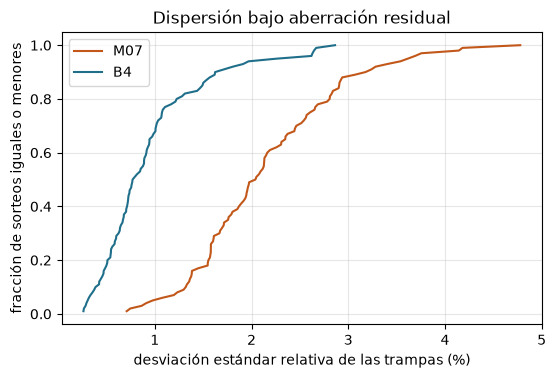

In [8]:
# la dispersión de las trampas sobre los 100 sorteos, ordenada: M07 frente a B4
fig, ax = plt.subplots(figsize=(6.2, 3.8))
share = np.arange(1, len(sig07) + 1) / len(sig07)
ax.plot(np.sort(sig07), share, label="M07", color="#c2571a")
ax.plot(np.sort(sig_b4), share, label="B4", color="#1f6f8b")
ax.set_xlabel("desviación estándar relativa de las trampas (%)")
ax.set_ylabel("fracción de sorteos iguales o menores")
ax.set_title("Dispersión bajo aberración residual")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

B4 tiene una dispersión media de 0,95 por ciento y un percentil 95 de 2,28 por ciento frente a 2,16 y 3,62 de M07: una razón de 1,59 en el percentil 95, con un intervalo bootstrap apareado de 1,30 a 2,02 al 90 por ciento, que deja fuera por abajo el criterio de 1,25. La eficiencia cambia en -1,1 por ciento, de 0,7050 a 0,6975, bien dentro del 10 permitido. B4 es más uniforme que M07 en los 100 sorteos, así que no son unos pocos afortunados: toda la curva azul queda a la izquierda de la naranja. La figura no dice la generalidad del diseño, porque los sorteos vienen de la misma distribución que describen los puntos sigma, y un diseño probado en la distribución para la que se construyó está probado dentro de la muestra. La celda siguiente cambia la distribución.

### Un residuo más ancho que el supuesto

Los mismos dos hologramas se evalúan con un residuo de desviación estándar de 0,03 ondas por modo, 1,5 veces el valor que supuso el diseño, de modo que su rms es 0,085 ondas. Un holograma diseñado para una distribución más angosta puede ser peor que uno nominal cuando la realidad es más ancha, o puede conservar parte de la ganancia.

In [9]:
# ambos hologramas bajo un residuo más ancho que aquel para el que se diseñó B4: 0.03 ondas por modo (rms
# 0.085 ondas)
wide07 = ensemble_stats(setup, res07.phi, traps, n=100, aberration=0.03)
wide_b4 = ensemble_stats(setup, res_b4.phi, traps, n=100, aberration=0.03)
for name, s in (("M07", wide07), ("B4", wide_b4)):
    print(f"{name}: eficiencia media {s['efficiency_mean']:.4f}  "
          f"percentil 95 {s['sigma_p95']:.2f} %")
print(f"razón de percentiles 95 M07 / B4: {wide07['sigma_p95'] / wide_b4['sigma_p95']:.2f}")

M07: eficiencia media 0.6314  percentil 95 5.84 %
B4: eficiencia media 0.6250  percentil 95 4.79 %
razón de percentiles 95 M07 / B4: 1.22


B4 conserva una parte de la ganancia y pierde la mayor parte: el percentil 95 es 5,84 por ciento para M07 y 4,79 para B4, una razón de 1,22, bajo el criterio de 1,25, y las eficiencias son 0,6314 y 0,6250. La afirmación de B4 vale para el residuo para el que se diseñó y se debilita rápido fuera de él. Un usuario del método debe entonces elegir $s_a$ a partir del instrumento, y el notebook no ofrece una fuente para su valor.

### Errores de apuntado

El dossier propuso que el mismo costo esperado podría cubrir también los errores de apuntado de las trampas, un desplazamiento de cada trampa respecto de su posición programada. El pipeline lleva esa opción, con un diseño muestreado (Adam sobre 8 sorteos aleatorios de la aberración y del desplazamiento de cada trampa), y la afirmación se acotó tras una primera medición, de modo que el notebook la informa como una medición. La celda evalúa tres hologramas bajo un error de apuntado solo, con cada trampa desplazada 0,15 bins de FFT rms (un punto mide unos dos bins de ancho) y sin aberración: M07, B4 diseñado para aberraciones, y un B4 diseñado con el error de apuntado.

In [10]:
# error de apuntado solo: trampas desplazadas 0.15 bins de FFT rms; M07, B4 y un B4 diseñado con ruido de
# apuntado
res_b4_pointing = b4_robust.run(setup, target, budget=Budget(30), rng=Rng(1), init=res07.phi, pointing_bins=0.15)
holograms = {
    "M07": res07.phi,
    "B4 (aberración)": res_b4.phi,
    "B4 (aberración + apuntado)": res_b4_pointing.phi,
}
pointing = {name: ensemble_stats(setup, phi, traps, n=100, aberration=0.0, pointing_bins=0.15)
            for name, phi in holograms.items()}
for name, s in pointing.items():
    print(f"{name:34s} eficiencia media {s['efficiency_mean']:.4f}  "
          f"percentil 95 {s['sigma_p95']:.2f} %")
base_p95 = pointing["M07"]["sigma_p95"]
for name, s in pointing.items():
    print(f"{name:34s} razón respecto de M07 {base_p95 / s['sigma_p95']:.2f}")

M07                                eficiencia media 0.7521  percentil 95 4.64 %
B4 (aberración)                    eficiencia media 0.7436  percentil 95 4.87 %
B4 (aberración + apuntado)         eficiencia media 0.7518  percentil 95 4.60 %
M07                                razón respecto de M07 1.00
B4 (aberración)                    razón respecto de M07 0.95
B4 (aberración + apuntado)         razón respecto de M07 1.01


Las barras comparan el percentil 95 de la dispersión de M07 y de B4 con solo aberración y con solo error de apuntado.

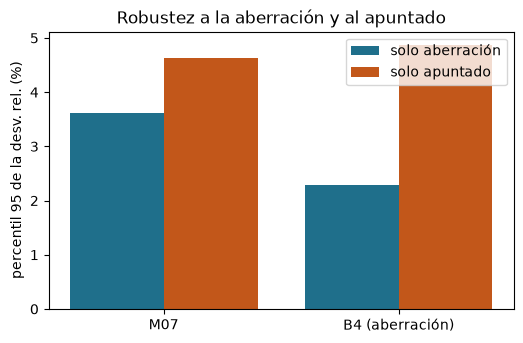

In [11]:
# percentil 95 de la dispersión, con y sin error de apuntado, para M07 y para B4
labels = ["M07", "B4 (aberración)"]
p95_aberration = [stats07["sigma_p95"], stats_b4["sigma_p95"]]
p95_pointing = [s["sigma_p95"] for s in list(pointing.values())[:2]]
slots = np.arange(2)
fig, ax = plt.subplots(figsize=(6.0, 3.6))
ax.bar(slots - 0.2, p95_aberration, 0.4, label="solo aberración", color="#1f6f8b")
ax.bar(slots + 0.2, p95_pointing, 0.4, label="solo apuntado", color="#c2571a")
ax.set_xticks(slots)
ax.set_xticklabels(labels)
ax.set_ylabel("percentil 95 de la desv. rel. (%)")
ax.set_title("Robustez a la aberración y al apuntado")
ax.legend()
plt.show()

Bajo un error de apuntado solo los tres hologramas son iguales con una diferencia de 6 por ciento: el percentil 95 de la dispersión es 4,64 por ciento para M07, 4,87 para B4 diseñado para aberraciones (una razón de 0,95, algo peor) y 4,60 para B4 diseñado con ruido de apuntado (1,01). El diseño que ve el error de apuntado no aprende de él. La explicación del propio pipeline es que una trampa desplazada pierde intensidad en proporción a la curvatura de su punto, y esa curvatura la fija el ancho del punto, que ningún patrón de fase puede cambiar sin ceder la mitad de la eficiencia pico; el notebook no probó esa explicación, solo el resultado. En la figura las barras azules, con solo aberración, difieren en un factor de 1,6 y las naranjas, con solo error de apuntado, en 5 por ciento como mucho (4,64 frente a 4,87). La afirmación de BS-4 se enuncia entonces para aberraciones, y el resultado de apuntado es un negativo que el benchmark también informa.

## Resultados

**Respuesta:** Un holograma puede hacerse robusto a los residuos de aberración que encontrará, dentro del ancho para el que se diseñó, y no a errores de apuntado. En las 16 trampas del caso C09, un residuo de 0,02 ondas rms en cada uno de los modos de Noll 4 a 11 convierte el holograma nominal de M07, casi exactamente uniforme en el sistema ideal, en uno con un percentil 95 de la dispersión de 3,62 por ciento y una eficiencia de 0,7050. B4, que optimiza el costo esperado sobre el residuo, tiene un percentil 95 de 2,28 por ciento: una razón de 1,59 con un intervalo apareado de 90 por ciento de 1,30 a 2,02, mejor en los 100 sorteos, con una eficiencia de 0,6975, 1,1 por ciento menor. La ganancia no sobrevive a un residuo 1,5 veces más ancho (razón 1,22, 5,84 frente a 4,79 por ciento), y no se extiende al apuntado: con cada trampa desplazada 0,15 bins el percentil 95 es 4,64 por ciento para M07 y 4,60 para un B4 diseñado con ese error, una razón de 1,01.

Lo que el notebook no muestra es el valor de $s_a$ para un instrumento real, que eligió la unidad; más de un holograma de partida; ni un error de apuntado mayor que 0,15 bins.

## Resumen

- Un holograma nominal, incluso uno exactamente uniforme en el sistema ideal, es frágil: un residuo de 0,057 ondas rms sube su dispersión media a 2,16 por ciento.
- B4 minimiza el costo esperado sobre el residuo con 16 puntos sigma y gradiente conjugado; su percentil 95 es 1,59 veces menor que el de M07 con 1,1 por ciento menos luz.
- La ganancia es apareada y consistente sobre los sorteos, pero está probada en la distribución que supuso el diseño.
- Con un residuo 1,5 veces más ancho la razón baja a 1,22, bajo el 1,25 del criterio.
- La robustez a errores de apuntado no se sigue del mismo diseño: la razón es 1,01 con un error de apuntado solo.

## Referencias

- Machu et al. Full-field-of-view aberration correction for large arrays of focused beams, the nearest prior work. https://arxiv.org/abs/2512.15967
- Kim et al. (2019). Large-scale uniform optical focus array generation with a phase spatial light modulator. Optics Letters 44, 3178. https://doi.org/10.1364/OL.44.003178
- Noll (1976). Zernike polynomials and atmospheric turbulence. Journal of the Optical Society of America 66, 207. https://doi.org/10.1364/JOSA.66.000207